# Atividade 6: participação por sexo e afazeres domésticos

Este notebook segue o fluxo do `Guia_plotagem.ipynb`: abre e trata os CSVs, renomeia as colunas, une períodos com `merge`, transforma os dados para o formato longo com `melt` e cria gráficos com a API `Figure`/`Axes` do matplotlib e o `barplot` do seaborn.

Nas Tabelas 5, as participações de homens e mulheres somam 100% em cada UF. Na Tabela 1.1.1, as horas de cuidados e afazeres domésticos são comparadas por sexo.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")

In [2]:
arquivos = {
    "2012": "Tabela5-sem_emprego_2012.csv",
    "2026": "Tabela5-sem_emprego_2026.csv",
    "horas": "Tabela1_1_1_horas.csv",
}

possiveis_pastas = [
    Path.cwd(),
    Path.cwd() / "Atividade6",
    Path.cwd() / "analise_dados" / "Atividade6",
]
pasta_dados = next(
    (
        pasta
        for pasta in possiveis_pastas
        if all((pasta / nome).is_file() for nome in arquivos.values())
    ),
    None,
)

if pasta_dados is None:
    raise FileNotFoundError("Não encontrei os arquivos da Atividade 6.")

caminho_2012 = pasta_dados / arquivos["2012"]
caminho_2026 = pasta_dados / arquivos["2026"]
caminho_horas = pasta_dados / arquivos["horas"]

pasta_dados

WindowsPath('//fserverb/homes/Python 3Etapa/analise_dados/Atividade6')

## 1. Abrir, renomear e unir os dados

As Tabelas 5 usam ponto e vírgula como separador, vírgula decimal e codificação UTF-8 com BOM. Depois da leitura, os nomes longos das colunas são encurtados com `rename` e os dois períodos são unidos por `Sigla`, `Código` e `Estado`.

In [3]:
t2012 = pd.read_csv(
    caminho_2012,
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
)
t2026 = pd.read_csv(
    caminho_2026,
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
)

t2012.head()

,Sigla,Código,Estado,Desocupados - homens (2012 T1),Desocupados - mulheres (2012 T1)
0,AC,12,Acre,45.3,54.7
1,AL,27,Alagoas,44.7,55.3
2,AM,13,Amazonas,47.5,52.5
3,AP,16,Amapá,48.1,51.9
4,BA,29,Bahia,43.8,56.2


In [4]:
t2012 = t2012.rename(
    columns={
        "Desocupados - homens (2012 T1)": "homens_2012",
        "Desocupados - mulheres (2012 T1)": "mulheres_2012",
    }
)
t2026 = t2026.rename(
    columns={
        "Desocupados - homens (2026 T1)": "homens_2026",
        "Desocupados - mulheres (2026 T1)": "mulheres_2026",
    }
)

assert (t2012["homens_2012"] + t2012["mulheres_2012"]).eq(100).all()
assert (t2026["homens_2026"] + t2026["mulheres_2026"]).eq(100).all()

chaves = ["Sigla", "Código", "Estado"]
comp = t2012.merge(
    t2026,
    on=chaves,
    how="inner",
    validate="one_to_one",
)
comp["var_mulheres_pp"] = (
    comp["mulheres_2026"] - comp["mulheres_2012"]
).round(1)

assert len(comp) == 27
comp[
    [
        "Sigla",
        "Código",
        "Estado",
        "homens_2012",
        "mulheres_2012",
        "homens_2026",
        "mulheres_2026",
        "var_mulheres_pp",
    ]
].head()

,Sigla,Código,Estado,homens_2012,mulheres_2012,homens_2026,mulheres_2026,var_mulheres_pp
0,AC,12,Acre,45.3,54.7,53.2,46.8,-7.9
1,AL,27,Alagoas,44.7,55.3,50.7,49.3,-6.0
2,AM,13,Amazonas,47.5,52.5,46.8,53.2,0.7
3,AP,16,Amapá,48.1,51.9,51.1,48.9,-3.0
4,BA,29,Bahia,43.8,56.2,44.7,55.3,-0.9


## 2. Formato longo para comparar sexo e ano

No formato largo, sexo e ano ficam escondidos nos nomes das colunas. `melt` mantém `Estado` e `Sigla`, transforma as quatro colunas de participação em linhas e cria as categorias `Sexo` e `Ano`. Assim, 27 UFs × 2 sexos × 2 períodos produzem 108 linhas.

In [5]:
longo = comp.melt(
    id_vars=["Estado", "Sigla"],
    value_vars=[
        "homens_2012",
        "mulheres_2012",
        "homens_2026",
        "mulheres_2026",
    ],
    var_name="Indicador",
    value_name="Participacao",
)

partes = longo["Indicador"].str.split("_", n=1, expand=True)
longo["Sexo"] = partes[0].map({"homens": "Homens", "mulheres": "Mulheres"})
longo["Ano"] = partes[1].map({"2012": "2012 T1", "2026": "2026 T1"})
longo = longo[["Estado", "Sigla", "Ano", "Sexo", "Participacao"]]

assert len(longo) == 108
assert not longo[["Ano", "Sexo", "Participacao"]].isna().any().any()
longo.head(8)

,Estado,Sigla,Ano,Sexo,Participacao
0,Acre,AC,2012 T1,Homens,45.3
1,Alagoas,AL,2012 T1,Homens,44.7
2,Amazonas,AM,2012 T1,Homens,47.5
3,Amapá,AP,2012 T1,Homens,48.1
4,Bahia,BA,2012 T1,Homens,43.8
5,Ceará,CE,2012 T1,Homens,51.1
6,Distrito Federal,DF,2012 T1,Homens,41.0
7,Espírito Santo,ES,2012 T1,Homens,46.4


### Barras horizontais agrupadas

Dois `Axes` na mesma `Figure` comparam os períodos com a mesma escala. O `hue="Sexo"` usa o formato longo, a linha em 50% marca a paridade e a ordem mantém os maiores valores no topo.

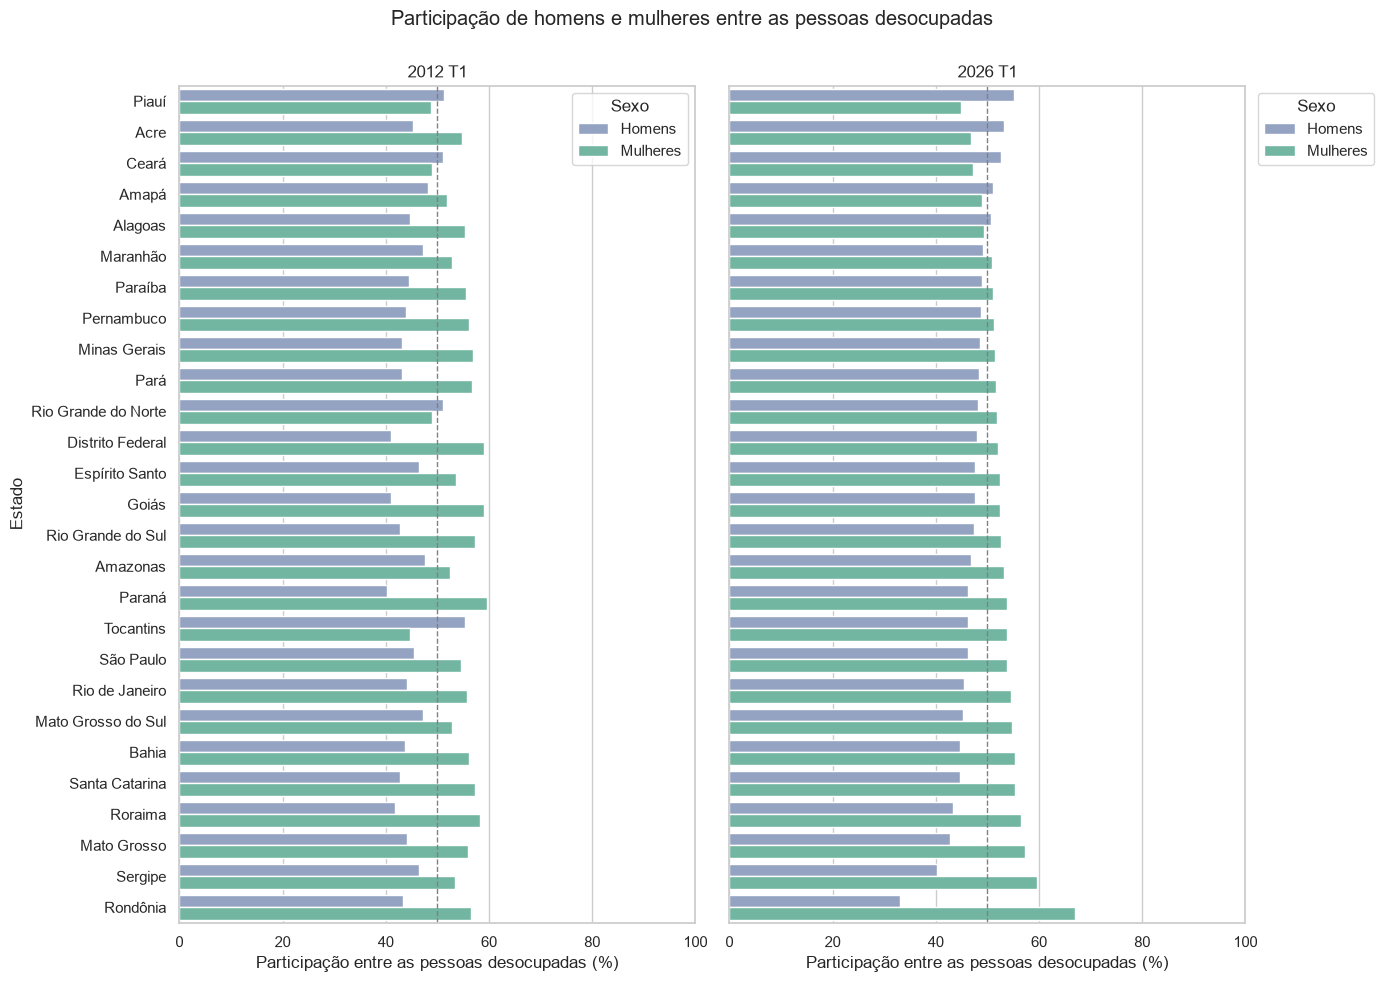

In [6]:
ordem = comp.sort_values("mulheres_2026")["Estado"].tolist()
cores = {"Homens": "#8da0cb", "Mulheres": "#66c2a5"}

fig, axes = plt.subplots(1, 2, figsize=(14, 10), sharex=True, sharey=True)
for ax, ano in zip(axes, ["2012 T1", "2026 T1"]):
    sns.barplot(
        data=longo.loc[longo["Ano"] == ano],
        x="Participacao",
        y="Estado",
        hue="Sexo",
        hue_order=["Homens", "Mulheres"],
        order=ordem,
        palette=cores,
        errorbar=None,
        ax=ax,
    )
    ax.axvline(50, color="gray", linestyle="--", linewidth=1)
    ax.set_title(ano)
    ax.set_xlabel("Participação entre as pessoas desocupadas (%)")
    ax.set_ylabel("Estado")
    ax.set_xlim(0, 100)

axes[1].legend(title="Sexo", bbox_to_anchor=(1.01, 1), loc="upper left")
fig.suptitle("Participação de homens e mulheres entre as pessoas desocupadas")
fig.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

As médias abaixo são médias simples das 27 UFs; elas não são ponderadas pela população de cada estado.

In [7]:
medias = (
    longo.groupby(["Ano", "Sexo"])["Participacao"]
    .mean()
    .round(1)
    .unstack()
)
medias

Sexo,Homens,Mulheres
Ano,,
2012 T1,45.4,54.6
2026 T1,47.0,53.0


### Variação da participação feminina

A mudança entre 2026 e 2012 é expressa em pontos percentuais (`pp`). Barras à direita do zero indicam aumento; à esquerda, queda. Uma linha vertical no zero separa os dois casos.

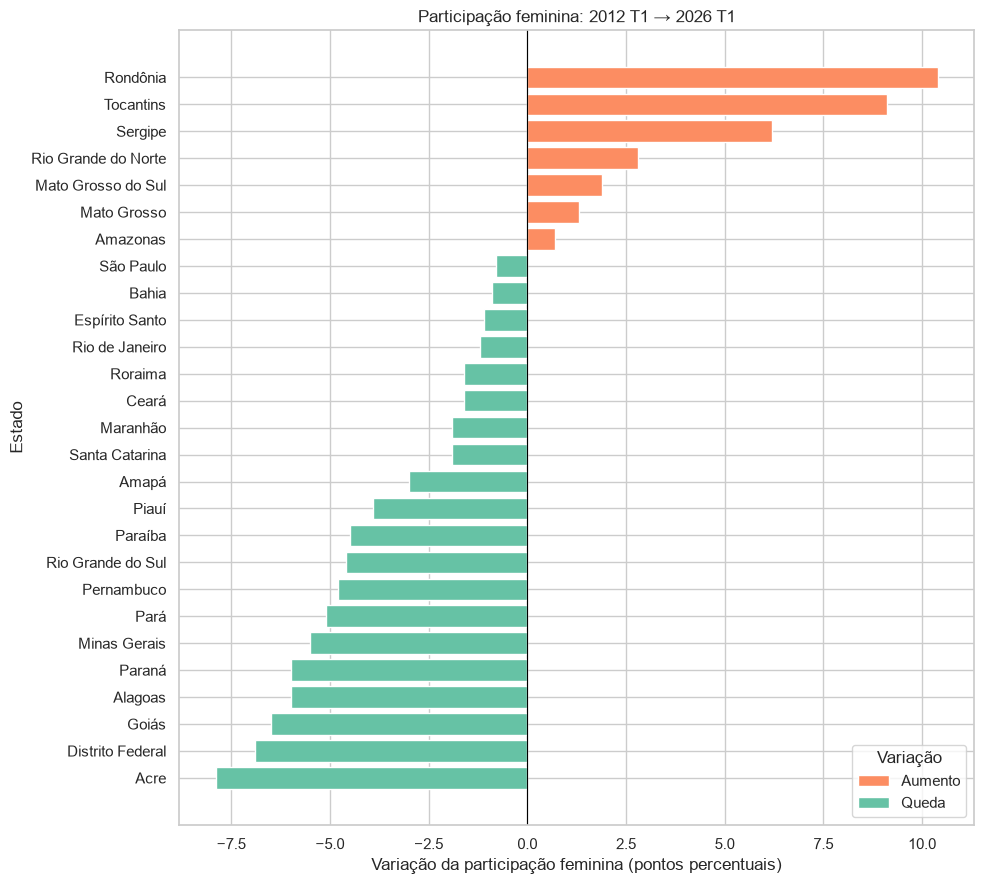

In [8]:
variacao = comp.sort_values("var_mulheres_pp")
cores_variacao = [
    "#fc8d62" if valor > 0 else "#66c2a5"
    for valor in variacao["var_mulheres_pp"]
]

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(
    variacao["Estado"],
    variacao["var_mulheres_pp"],
    color=cores_variacao,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Variação da participação feminina (pontos percentuais)")
ax.set_ylabel("Estado")
ax.set_title("Participação feminina: 2012 T1 → 2026 T1")
ax.legend(
    handles=[
        Patch(facecolor="#fc8d62", label="Aumento"),
        Patch(facecolor="#66c2a5", label="Queda"),
    ],
    title="Variação",
    loc="lower right",
)
fig.tight_layout()
plt.show()

### Dispersão entre os períodos

Cada ponto representa uma UF. A diagonal `y = x` compara 2012 com 2026: pontos acima da linha tiveram aumento da participação feminina e pontos abaixo, queda. `annotate` acrescenta a sigla de cada estado.

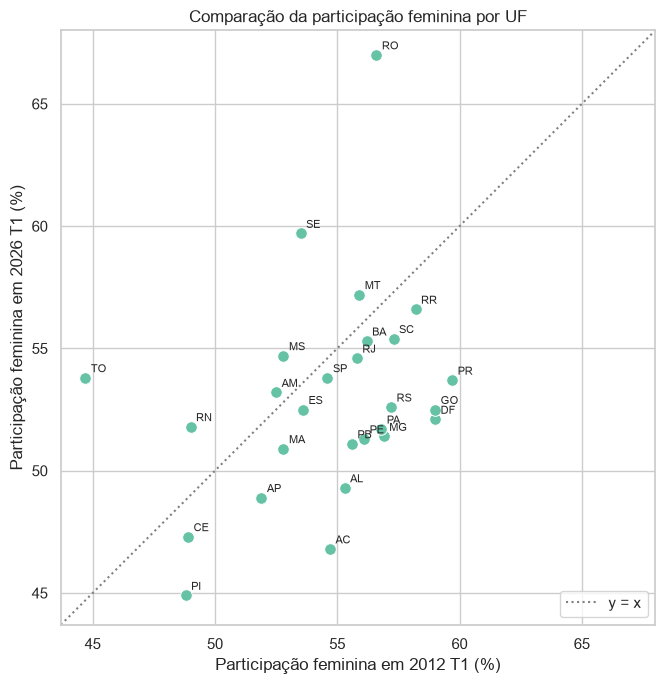

In [9]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(
    comp["mulheres_2012"],
    comp["mulheres_2026"],
    s=70,
    color="#66c2a5",
    edgecolor="white",
    linewidth=0.7,
)

for _, linha in comp.iterrows():
    ax.annotate(
        linha["Sigla"],
        (linha["mulheres_2012"], linha["mulheres_2026"]),
        textcoords="offset points",
        xytext=(4, 4),
        fontsize=8,
    )

participacoes = pd.concat(
    [comp["mulheres_2012"], comp["mulheres_2026"]]
)
limites = [max(0, participacoes.min() - 1), min(100, participacoes.max() + 1)]
ax.plot(limites, limites, linestyle=":", color="gray", label="y = x")
ax.set_xlim(limites)
ax.set_ylim(limites)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Participação feminina em 2012 T1 (%)")
ax.set_ylabel("Participação feminina em 2026 T1 (%)")
ax.set_title("Comparação da participação feminina por UF")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### Linhas para as maiores mudanças

Com dois períodos, cada segmento mostra a passagem de 2012 para 2026. O `groupby("Sigla")` cria uma série por estado, como no guia.

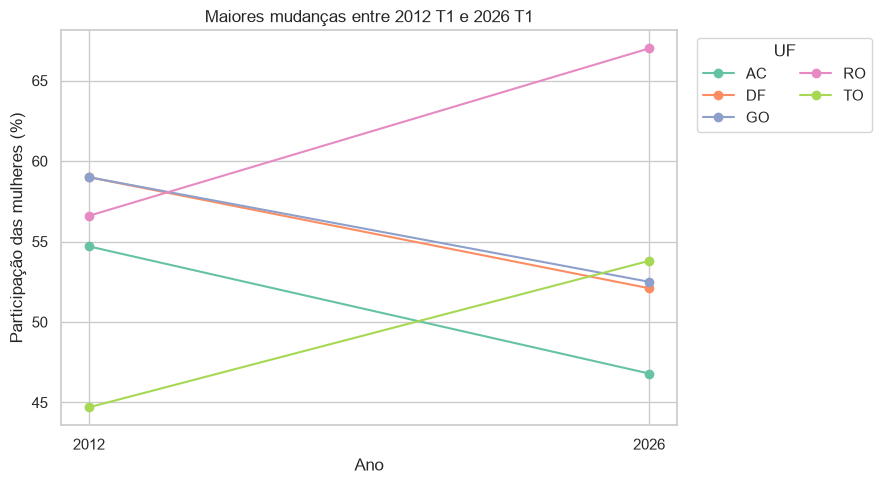

In [10]:
indices = comp["var_mulheres_pp"].abs().nlargest(5).index
maiores_mudancas = comp.loc[indices, "Sigla"].tolist()

fig, ax = plt.subplots(figsize=(9, 5))
for sigla, grupo in comp[comp["Sigla"].isin(maiores_mudancas)].groupby("Sigla"):
    ax.plot(
        [2012, 2026],
        [grupo["mulheres_2012"].iloc[0], grupo["mulheres_2026"].iloc[0]],
        marker="o",
        markersize=6,
        linewidth=1.5,
        label=sigla,
    )

ax.set_xticks([2012, 2026])
ax.set_xlabel("Ano")
ax.set_ylabel("Participação das mulheres (%)")
ax.set_title("Maiores mudanças entre 2012 T1 e 2026 T1")
ax.legend(title="UF", ncol=2, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

## 3. Cruzamento com as horas de afazeres domésticos

A Tabela 1.1.1 traz as horas semanais de cuidados e afazeres domésticos. Brasil e as cinco regiões são removidos do cruzamento estadual. Para cada UF, as médias de homens e mulheres são médias simples das categorias branca e preta ou parda.

In [11]:
horas = pd.read_csv(
    caminho_horas,
    sep=";",
    decimal=".",
    encoding="utf-8-sig",
)
colunas_numericas = [coluna for coluna in horas.columns if coluna != "uf_regiao"]
horas[colunas_numericas] = horas[colunas_numericas].apply(
    pd.to_numeric,
    errors="raise",
)

agregados = {"Brasil", "Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"}
linha_brasil = horas.loc[horas["uf_regiao"] == "Brasil"].iloc[0]
media_brasil = pd.Series(
    {
        "Total": linha_brasil["total"],
        "Homens": linha_brasil[["homem_branca", "homem_preta_parda"]].mean(),
        "Mulheres": linha_brasil[["mulher_branca", "mulher_preta_parda"]].mean(),
    }
)

estados_horas = horas.loc[~horas["uf_regiao"].isin(agregados)].copy()
estados_horas["horas_homem"] = estados_horas[
    ["homem_branca", "homem_preta_parda"]
].mean(axis=1, skipna=False)
estados_horas["horas_mulher"] = estados_horas[
    ["mulher_branca", "mulher_preta_parda"]
].mean(axis=1, skipna=False)
estados_horas = estados_horas.rename(
    columns={"uf_regiao": "Estado", "total": "horas_total"}
)

assert len(estados_horas) == 27
assert not estados_horas[["horas_total", "horas_homem", "horas_mulher"]].isna().any().any()
estados_horas[["Estado", "horas_total", "horas_homem", "horas_mulher"]].head()

,Estado,horas_total,horas_homem,horas_mulher
2,Rondônia,17.014162,12.327603,20.737148
3,Acre,13.606903,10.241551,16.420553
4,Amazonas,16.807290,12.527814,19.740977
5,Roraima,13.639257,10.645702,16.348061
6,Pará,16.474268,11.275506,20.713127


In [12]:
analise = comp.merge(
    estados_horas[["Estado", "horas_total", "horas_homem", "horas_mulher"]],
    on="Estado",
    how="inner",
    validate="one_to_one",
)
analise["gap_horas"] = (
    analise["horas_mulher"] - analise["horas_homem"]
).round(2)

assert len(analise) == 27
analise[
    [
        "Sigla",
        "Estado",
        "mulheres_2012",
        "mulheres_2026",
        "var_mulheres_pp",
        "horas_homem",
        "horas_mulher",
        "gap_horas",
    ]
].head()

,Sigla,Estado,mulheres_2012,mulheres_2026,var_mulheres_pp,horas_homem,horas_mulher,gap_horas
0,AC,Acre,54.7,46.8,-7.9,10.241551,16.420553,6.18
1,AL,Alagoas,55.3,49.3,-6.0,12.739500,24.975146,12.24
2,AM,Amazonas,52.5,53.2,0.7,12.527814,19.740977,7.21
3,AP,Amapá,51.9,48.9,-3.0,10.933132,16.278533,5.35
4,BA,Bahia,56.2,55.3,-0.9,10.767240,22.894925,12.13


### Dispersão das horas por sexo

Na diagonal `y = x`, homens e mulheres teriam a mesma média de horas. Os pontos acima da linha mostram UFs em que as mulheres dedicam mais horas a essas atividades.

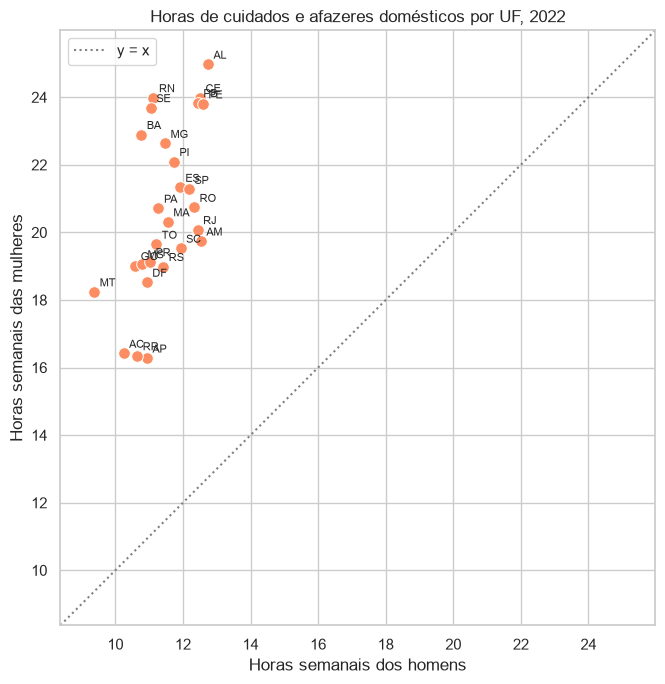

In [13]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(
    analise["horas_homem"],
    analise["horas_mulher"],
    s=70,
    color="#fc8d62",
    edgecolor="white",
    linewidth=0.7,
)

for _, linha in analise.iterrows():
    ax.annotate(
        linha["Sigla"],
        (linha["horas_homem"], linha["horas_mulher"]),
        textcoords="offset points",
        xytext=(4, 4),
        fontsize=8,
    )

valores_horas = analise[["horas_homem", "horas_mulher"]].to_numpy()
limites_horas = [valores_horas.min() - 1, valores_horas.max() + 1]
ax.plot(limites_horas, limites_horas, linestyle=":", color="gray", label="y = x")
ax.set_xlim(limites_horas)
ax.set_ylim(limites_horas)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Horas semanais dos homens")
ax.set_ylabel("Horas semanais das mulheres")
ax.set_title("Horas de cuidados e afazeres domésticos por UF, 2022")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## 4. Resultados

As médias das participações são simples e consideram as 27 UFs com o mesmo peso. As médias nacionais de horas também são simples entre as categorias branca e preta ou parda; por isso, os rótulos deixam essa limitação explícita.

In [14]:
abaixo_50 = comp.loc[comp["mulheres_2026"] < 50, "Estado"].tolist()
acima_media_mulher = analise.loc[
    analise["horas_mulher"] > media_brasil["Mulheres"],
    "Estado",
].tolist()

resultados = pd.Series(
    {
        "Média simples das UFs — homens 2012 T1 (%)": round(comp["homens_2012"].mean(), 1),
        "Média simples das UFs — mulheres 2012 T1 (%)": round(comp["mulheres_2012"].mean(), 1),
        "Média simples das UFs — homens 2026 T1 (%)": round(comp["homens_2026"].mean(), 1),
        "Média simples das UFs — mulheres 2026 T1 (%)": round(comp["mulheres_2026"].mean(), 1),
        "Variação média da participação feminina (pp)": round(comp["var_mulheres_pp"].mean(), 1),
        "Média simples do Brasil — total (horas)": round(media_brasil["Total"], 2),
        "Média simples do Brasil — homens (horas)": round(media_brasil["Homens"], 2),
        "Média simples do Brasil — mulheres (horas)": round(media_brasil["Mulheres"], 2),
        "UFs com menos de 50% de mulheres em 2026 T1": ", ".join(abaixo_50),
        "UFs acima da média simples feminina do Brasil": ", ".join(acima_media_mulher),
    }
)
resultados

Média simples das UFs — homens 2012 T1 (%)                                                    45.4
Média simples das UFs — mulheres 2012 T1 (%)                                                  54.6
Média simples das UFs — homens 2026 T1 (%)                                                    47.0
Média simples das UFs — mulheres 2026 T1 (%)                                                  53.0
Variação média da participação feminina (pp)                                                  -1.6
Média simples do Brasil — total (horas)                                                      16.99
Média simples do Brasil — homens (horas)                                                     11.73
Média simples do Brasil — mulheres (horas)                                                   21.22
UFs com menos de 50% de mulheres em 2026 T1                     Acre, Alagoas, Amapá, Ceará, Piauí
UFs acima da média simples feminina do Brasil    Alagoas, Bahia, Ceará, Espírito Santo, Minas G...
dtype: obj

As correlações são apenas exploratórias entre UFs. Elas misturam períodos diferentes, não estabelecem relação de causa e efeito e não corrigem as diferenças de população entre os estados.

In [15]:
correlacoes = pd.Series(
    {
        "Participação feminina 2026 × horas das mulheres": analise["mulheres_2026"].corr(
            analise["horas_mulher"]
        ),
        "Variação feminina × diferença de horas": analise["var_mulheres_pp"].corr(
            analise["gap_horas"]
        ),
    }
)
correlacoes.round(3)

Participação feminina 2026 × horas das mulheres   -0.087
Variação feminina × diferença de horas             0.108
dtype: float64

In [16]:
ranking = comp.assign(
    posicao=comp["mulheres_2026"].rank(ascending=False, method="min").astype(int)
)
ranking.sort_values("posicao")[
    ["posicao", "Sigla", "Estado", "mulheres_2026"]
].head(10)

,posicao,Sigla,Estado,mulheres_2026
20,1,RO,Rondônia,67.0
24,2,SE,Sergipe,59.7
12,3,MT,Mato Grosso,57.2
21,4,RR,Roraima,56.6
23,5,SC,Santa Catarina,55.4
4,6,BA,Bahia,55.3
11,7,MS,Mato Grosso do Sul,54.7
18,8,RJ,Rio de Janeiro,54.6
25,9,SP,São Paulo,53.8
26,9,TO,Tocantins,53.8
